In [3]:
!pip install pandas numpy matplotlib seaborn gensim scikit-learn joblib

TAHAP 1: INFORMASI DATASET
Jumlah berita       : 200
Jumlah fitur teks   : 5

Distribusi kelas:
label
sport      100
finance    100
Name: count, dtype: int64

Persentase kelas:
label
sport      50.0
finance    50.0
Name: count, dtype: float64

TAHAP 2: PEMBAGIAN DATA
Data latih: 160
Data uji  : 40



TAHAP 3: WORD2VEC SKIP-GRAM
Arsitektur       : Skip-gram
Dimensi vektor   : 100
Ukuran vocabulary: 4740
Window           : 5
Epoch            : 20
Min count        : 1

Contoh kosakata:
['jadi', 'sebut', 'indonesia', 'jakarta', 'lebih', 'laku', 'tahun', 'kata', 'satu', 'rp', 'menteri', 'atlet', 'hingga', 'dapat', 'hasil', 'besar', 'baik', 'kembang', 'jalan', 'sama']

Vektor kata 'saham':
[ 0.15741213 -0.15845305  0.09165239  0.42936224 -0.28438658 -0.5529851
  0.62439114 -0.02090218 -0.12178323 -0.23060064  0.18280633 -0.29782093
  0.46445003  0.22522904 -0.37737164  0.12988988  0.08790872 -0.29722857
 -0.14618094  0.28362283  0.3643575  -0.23653181 -0.11821389 -0.03403918
 -0.59498847  0.43709    -0.28923413 -0.12932609 -0.27846417 -0.00383138
  0.44357422 -0.20293851  0.6900599   0.47764394 -0.46786198  0.1078791
 -0.26079944 -0.1085584   0.1555451  -0.03582622 -0.36266607  0.14055385
  0.01232917 -0.16673785 -0.22689658 -0.47648787  0.38617125 -0.42806014
 -0.18266134 -0.5212916  -

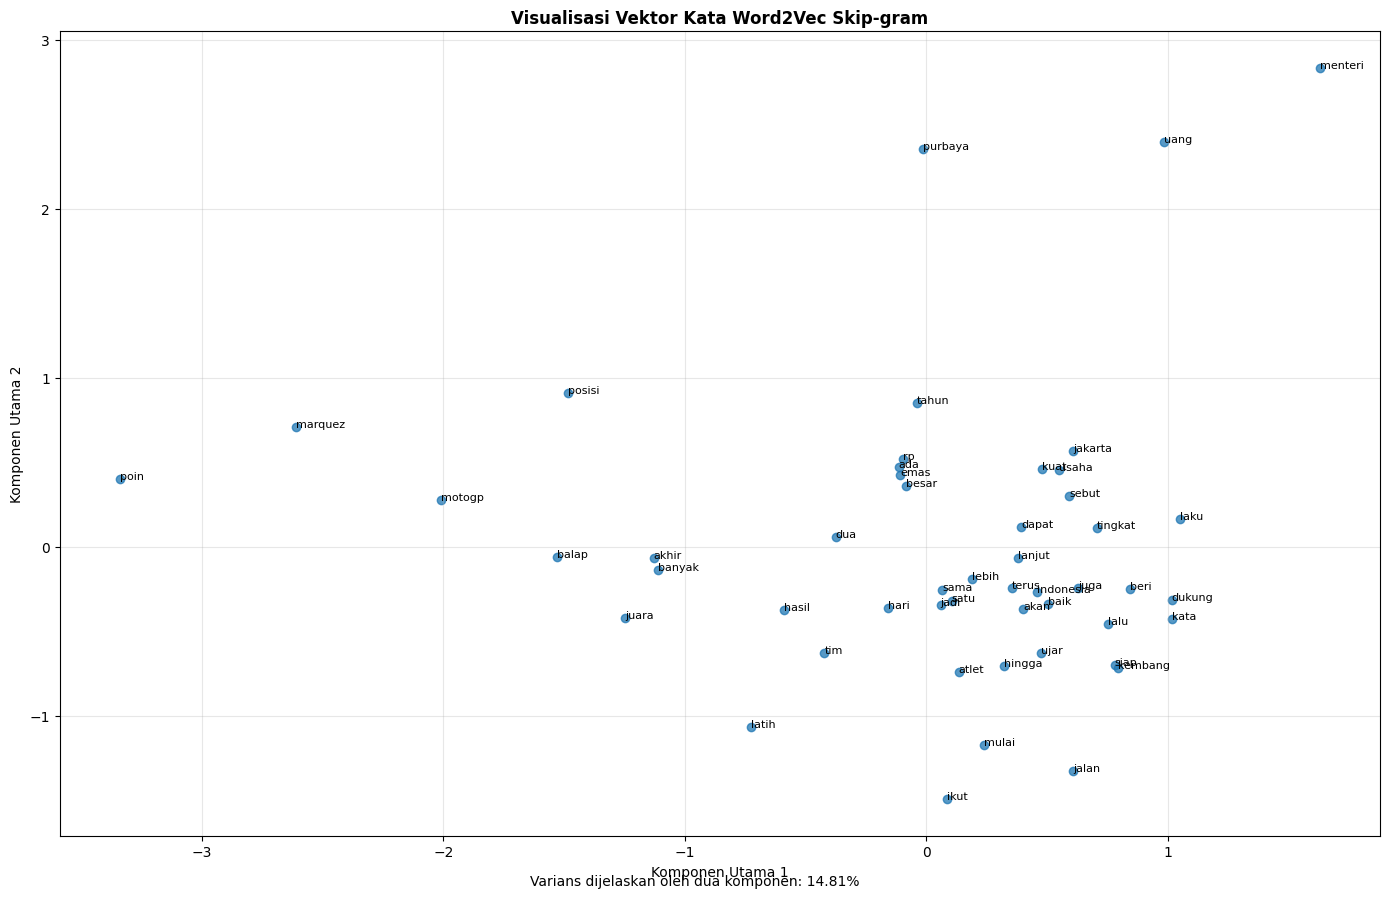


TAHAP 6: VEKTOR DOKUMEN
Vektor latih: (160, 100)
Vektor uji  : (40, 100)
Vektor nol pada data latih: 0
Vektor nol pada data uji  : 0

TAHAP 7: PCA
Dimensi sebelum PCA : 100
Dimensi setelah PCA : 11
Varians dipertahankan: 86.30%
Bentuk data latih   : (160, 11)
Bentuk data uji     : (40, 11)

HASIL MODEL: Word2Vec + GNB tanpa PCA
Accuracy          : 97.50%
Balanced Accuracy : 97.50%
Macro Precision   : 97.62%
Macro Recall      : 97.50%
Macro F1          : 97.50%
Weighted F1       : 97.50%

Classification Report:
              precision    recall  f1-score   support

     Finance       0.95      1.00      0.98        20
       Sport       1.00      0.95      0.97        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40


HASIL MODEL: Word2Vec + PCA + GNB
Accuracy          : 87.50%
Balanced Accuracy : 87.50%
Macro Precision   : 90.00%
Macro Recall      : 87.50%
Macro F1     

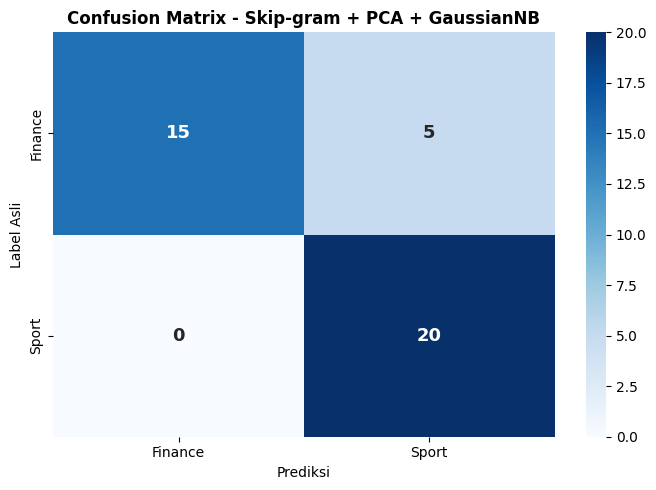

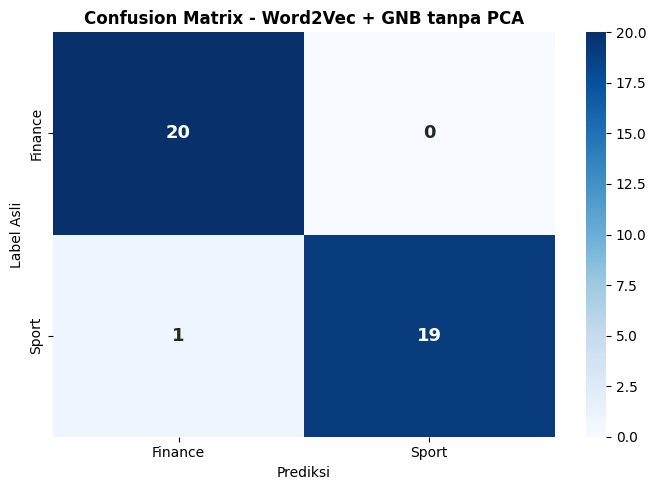


PREDIKSI BERITA BARU - MODEL UTAMA
Teks berita    : IHSG bergerak menguat seiring peningkatan volume transaksi saham di pasar modal
Hasil prediksi : Finance

Probabilitas model:
Finance: 100.00%
Sport: 0.00%

PROSES SELESAI
Folder output: hasil_skipgram
Artefak yang disimpan:
- w2v_model.model
- pca_model.pkl
- gnb_model.pkl
- metadata_model.pkl
- model_pembanding_terbaik.pkl
- metadata_pembanding.pkl
- perbandingan_model.csv
- hasil_prediksi_data_uji.csv
- prediksi_model_terbaik.csv
- hasil_vektor_kata_skipgram.csv
- hasil_kemiripan_kata_skipgram.csv
- visualisasi_skipgram_pca.png
- confusion_matrix_skipgram.png
- confusion_matrix_model_terbaik.png


In [4]:

# ==============================================================================
# KLASIFIKASI BERITA DETIK
# Word2Vec Skip-gram + PCA + Gaussian Naive Bayes
# Pembanding: GaussianNB tanpa PCA, Logistic Regression, TF-IDF + Linear SVM

import os
import random
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from gensim.models import Word2Vec

from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

# ==============================================================================
# KONFIGURASI
# ==============================================================================

SEED = 42
TEST_SIZE = 0.20
VECTOR_SIZE = 100
WINDOW = 5
EPOCHS = 20
MIN_COUNT = 1
PCA_VARIANCE = 0.85

DATA_PATH = "detik_preprocessed.csv"
OUTPUT_DIR = "hasil_skipgram"

os.makedirs(OUTPUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
warnings.filterwarnings("default")

LABEL_MAP = {
    "finance": 0,
    "sport": 1,
}

LABEL_NAMES = ["Finance", "Sport"]


# ==============================================================================
# TAHAP 1: MEMUAT DAN MEMVALIDASI DATASET
# ==============================================================================

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"File dataset tidak ditemukan: {DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH)

required_columns = {"isi_berita_clean", "label"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Kolom dataset tidak ditemukan: {missing_columns}"
    )

df = df.dropna(subset=["label"]).copy()

df["label"] = (
    df["label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df["isi_berita_clean"] = (
    df["isi_berita_clean"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Mempertahankan dua kategori yang akan diklasifikasikan.
df = df[df["label"].isin(LABEL_MAP)].copy()

# Menghapus dokumen kosong.
df = df[
    df["isi_berita_clean"].str.len() > 0
].copy()

# Menghapus duplikat teks persis untuk mengurangi risiko
# berita yang sama masuk ke data latih dan data uji.
df = df.drop_duplicates(
    subset=["isi_berita_clean"]
).reset_index(drop=True)

if df.empty:
    raise ValueError(
        "Dataset tidak memiliki teks dengan label Finance atau Sport."
    )

df["label_encoded"] = df["label"].map(LABEL_MAP)

# Tokenisasi sesuai asumsi bahwa dataset sudah dipreprocessing.
df["tokens"] = df["isi_berita_clean"].apply(
    lambda text: text.lower().split()
)

df = df[
    df["tokens"].map(len) > 0
].reset_index(drop=True)

if df.empty:
    raise ValueError("Tidak ada dokumen yang dapat diproses.")

if df["label"].nunique() != 2:
    raise ValueError(
        "Dataset harus memiliki kedua kelas: Finance dan Sport."
    )

class_counts = df["label"].value_counts()

if class_counts.min() < 2:
    raise ValueError(
        "Setiap kelas harus memiliki minimal 2 dokumen "
        "untuk pembagian data terstratifikasi."
    )

print("=" * 75)
print("TAHAP 1: INFORMASI DATASET")
print("=" * 75)
print(f"Jumlah berita       : {len(df)}")
print(f"Jumlah fitur teks   : {len(df.columns)}")
print("\nDistribusi kelas:")
print(class_counts)
print("\nPersentase kelas:")
print((class_counts / len(df) * 100).round(2))


# ==============================================================================
# TAHAP 2: MEMBAGI DATA LATIH DAN DATA UJI
# ==============================================================================

# Split dilakukan sebelum melatih Word2Vec, TF-IDF, dan PCA.
# Stratifikasi mempertahankan proporsi kelas semirip mungkin.

indices = np.arange(len(df))
labels = df["label_encoded"].to_numpy(dtype=int)

train_idx, test_idx = train_test_split(
    indices,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=labels,
)

train_df = df.iloc[train_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

sentences_train = train_df["tokens"].tolist()
sentences_test = test_df["tokens"].tolist()

texts_train = train_df["isi_berita_clean"].tolist()
texts_test = test_df["isi_berita_clean"].tolist()

y_train = train_df["label_encoded"].to_numpy(dtype=int)
y_test = test_df["label_encoded"].to_numpy(dtype=int)

print("\n" + "=" * 75)
print("TAHAP 2: PEMBAGIAN DATA")
print("=" * 75)
print(f"Data latih: {len(train_df)}")
print(f"Data uji  : {len(test_df)}")


# ==============================================================================
# TAHAP 3: MELATIH WORD2VEC SKIP-GRAM
# ==============================================================================

w2v_model = Word2Vec(
    sentences=sentences_train,
    vector_size=VECTOR_SIZE,
    window=WINDOW,
    min_count=MIN_COUNT,
    sg=1,
    workers=1,
    seed=SEED,
    epochs=EPOCHS,
    sample=1e-3,
)

print("\n" + "=" * 75)
print("TAHAP 3: WORD2VEC SKIP-GRAM")
print("=" * 75)
print(f"Arsitektur       : Skip-gram")
print(f"Dimensi vektor   : {w2v_model.vector_size}")
print(f"Ukuran vocabulary: {len(w2v_model.wv)}")
print(f"Window           : {WINDOW}")
print(f"Epoch            : {EPOCHS}")
print(f"Min count        : {MIN_COUNT}")

print("\nContoh kosakata:")
print(w2v_model.wv.index_to_key[:20])

w2v_model.save(
    os.path.join(OUTPUT_DIR, "w2v_model.model")
)


# ==============================================================================
# TAHAP 4: ANALISIS VEKTOR DAN KEMIRIPAN KATA
# ==============================================================================

kata_target = "saham"

if kata_target not in w2v_model.wv:
    kata_target = w2v_model.wv.index_to_key[0]

vector = w2v_model.wv[kata_target]

print(f"\nVektor kata '{kata_target}':")
print(vector)

similar_words = []

if len(w2v_model.wv) > 1:
    similar_words = w2v_model.wv.most_similar(
        kata_target,
        topn=min(10, len(w2v_model.wv) - 1),
    )

print(f"\nKata paling mirip dengan '{kata_target}':")

for word, similarity in similar_words:
    print(f"{word:<25} {similarity:.4f}")

vector_df = pd.DataFrame(
    [vector],
    columns=[
        f"dimensi_{i+1}"
        for i in range(w2v_model.vector_size)
    ],
)

vector_df.insert(0, "kata", kata_target)

vector_df.to_csv(
    os.path.join(
        OUTPUT_DIR, "hasil_vektor_kata_skipgram.csv"
    ),
    index=False,
)

similarity_df = pd.DataFrame(
    similar_words,
    columns=["kata", "skor_kemiripan"],
)

similarity_df.to_csv(
    os.path.join(
        OUTPUT_DIR, "hasil_kemiripan_kata_skipgram.csv"
    ),
    index=False,
)


# ==============================================================================
# TAHAP 5: VISUALISASI VEKTOR KATA MENGGUNAKAN PCA 2D
# ==============================================================================

jumlah_kata = min(50, len(w2v_model.wv))
kata_visual = w2v_model.wv.index_to_key[:jumlah_kata]

if len(kata_visual) >= 2:
    vektor_visual = np.array(
        [w2v_model.wv[word] for word in kata_visual]
    )

    pca_visual = PCA(
        n_components=2,
        random_state=SEED,
    )

    vektor_2d = pca_visual.fit_transform(vektor_visual)

    plt.figure(figsize=(14, 9))
    plt.scatter(
        vektor_2d[:, 0],
        vektor_2d[:, 1],
        alpha=0.75,
    )

    for i, word in enumerate(kata_visual):
        plt.annotate(
            word,
            (vektor_2d[i, 0], vektor_2d[i, 1]),
            fontsize=8,
        )

    variance_visual = (
        pca_visual.explained_variance_ratio_.sum() * 100
    )

    plt.title(
        "Visualisasi Vektor Kata Word2Vec Skip-gram",
        fontweight="bold",
    )
    plt.xlabel("Komponen Utama 1")
    plt.ylabel("Komponen Utama 2")
    plt.figtext(
        0.5,
        0.01,
        f"Varians dijelaskan oleh dua komponen: "
        f"{variance_visual:.2f}%",
        ha="center",
    )
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR, "visualisasi_skipgram_pca.png"
        ),
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()


# ==============================================================================
# TAHAP 6: EKSTRAKSI VEKTOR DOKUMEN
# ==============================================================================

def get_document_vector(tokens, model):
    """
    Menghasilkan vektor dokumen dari rata-rata vektor kata
    yang dikenal oleh model Word2Vec.
    """

    valid_vectors = [
        model.wv[token]
        for token in tokens
        if token in model.wv
    ]

    if not valid_vectors:
        return np.zeros(
            model.vector_size,
            dtype=np.float32,
        )

    return np.mean(
        valid_vectors,
        axis=0,
        dtype=np.float32,
    )


X_train_vec = np.vstack([
    get_document_vector(tokens, w2v_model)
    for tokens in sentences_train
])

X_test_vec = np.vstack([
    get_document_vector(tokens, w2v_model)
    for tokens in sentences_test
])

print("\n" + "=" * 75)
print("TAHAP 6: VEKTOR DOKUMEN")
print("=" * 75)
print(f"Vektor latih: {X_train_vec.shape}")
print(f"Vektor uji  : {X_test_vec.shape}")

# Pemeriksaan dokumen yang seluruh katanya tidak dikenal model.
zero_train = np.all(X_train_vec == 0, axis=1).sum()
zero_test = np.all(X_test_vec == 0, axis=1).sum()

print(f"Vektor nol pada data latih: {zero_train}")
print(f"Vektor nol pada data uji  : {zero_test}")


# ==============================================================================
# TAHAP 7: REDUKSI DIMENSI PCA
# ==============================================================================

if min(X_train_vec.shape) < 2:
    raise ValueError(
        "Data latih terlalu sedikit untuk menjalankan PCA."
    )

pca = PCA(
    n_components=PCA_VARIANCE,
    svd_solver="full",
)

X_train_pca = pca.fit_transform(X_train_vec)
X_test_pca = pca.transform(X_test_vec)

retained_variance = (
    pca.explained_variance_ratio_.sum() * 100
)

print("\n" + "=" * 75)
print("TAHAP 7: PCA")
print("=" * 75)
print(f"Dimensi sebelum PCA : {X_train_vec.shape[1]}")
print(f"Dimensi setelah PCA : {X_train_pca.shape[1]}")
print(f"Varians dipertahankan: {retained_variance:.2f}%")
print(f"Bentuk data latih   : {X_train_pca.shape}")
print(f"Bentuk data uji     : {X_test_pca.shape}")

joblib.dump(
    pca,
    os.path.join(OUTPUT_DIR, "pca_model.pkl"),
)


# ==============================================================================
# TAHAP 8: MEMBANGUN DAN MEMBANDINGKAN MODEL
# ==============================================================================

# Model utama tetap Word2Vec + PCA + GaussianNB.
# Model lain dipakai sebagai pembanding pada data uji yang sama.

models = {
    "Word2Vec + GNB tanpa PCA": GaussianNB(),

    "Word2Vec + PCA + GNB": GaussianNB(),

    "Word2Vec + Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=SEED,
        ),
    ),

    "Word2Vec + PCA + Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=SEED,
        ),
    ),

    "TF-IDF + Linear SVM": make_pipeline(
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=1,
            max_df=0.98,
            sublinear_tf=True,
            strip_accents=None,
        ),
        LinearSVC(
            class_weight="balanced",
            random_state=SEED,
        ),
    ),
}

model_inputs = {
    "Word2Vec + GNB tanpa PCA": (
        X_train_vec, X_test_vec
    ),

    "Word2Vec + PCA + GNB": (
        X_train_pca, X_test_pca
    ),

    "Word2Vec + Logistic Regression": (
        X_train_vec, X_test_vec
    ),

    "Word2Vec + PCA + Logistic Regression": (
        X_train_pca, X_test_pca
    ),

    "TF-IDF + Linear SVM": (
        texts_train, texts_test
    ),
}

results = []
predictions = {}
fitted_models = {}

for name, model in models.items():

    Xtr, Xte = model_inputs[name]

    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)

    fitted_models[name] = model
    predictions[name] = y_pred

    acc = accuracy_score(y_test, y_pred)

    balanced_acc = balanced_accuracy_score(
        y_test, y_pred
    )

    precision_macro = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0,
    )

    recall_macro = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0,
    )

    f1_macro = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0,
    )

    f1_weighted = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0,
    )

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Balanced Accuracy": balanced_acc,
        "Macro Precision": precision_macro,
        "Macro Recall": recall_macro,
        "Macro F1": f1_macro,
        "Weighted F1": f1_weighted,
    })

    print("\n" + "=" * 75)
    print(f"HASIL MODEL: {name}")
    print("=" * 75)

    print(f"Accuracy          : {acc * 100:.2f}%")
    print(f"Balanced Accuracy : {balanced_acc * 100:.2f}%")
    print(f"Macro Precision   : {precision_macro * 100:.2f}%")
    print(f"Macro Recall      : {recall_macro * 100:.2f}%")
    print(f"Macro F1          : {f1_macro * 100:.2f}%")
    print(f"Weighted F1       : {f1_weighted * 100:.2f}%")

    print("\nClassification Report:")

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=LABEL_NAMES,
            zero_division=0,
        )
    )


# ==============================================================================
# TAHAP 9: MENYIMPAN PERBANDINGAN DAN MEMILIH MODEL TERBAIK
# ==============================================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False,
).reset_index(drop=True)

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR, "perbandingan_model.csv"
    ),
    index=False,
)

print("\n" + "=" * 75)
print("PERBANDINGAN SELURUH MODEL")
print("=" * 75)
print(results_df.to_string(index=False, float_format="%.4f"))

# Pemilihan ini berdasarkan Macro F1 pada test set.
# Skor tersebut berguna untuk perbandingan awal, tetapi bukan
# estimasi performa final yang bebas bias pemilihan model.
best_name = results_df.loc[0, "Model"]
best_model = fitted_models[best_name]
best_pred = predictions[best_name]

print(f"\nModel dengan Macro F1 tertinggi: {best_name}")

# Simpan model pembanding terbaik.
# TF-IDF pipeline menyertakan vectorizer sehingga dapat
# menerima teks mentah yang sudah dipreprocessing.
joblib.dump(
    best_model,
    os.path.join(OUTPUT_DIR, "model_pembanding_terbaik.pkl"),
)

joblib.dump(
    {
        "model_name": best_name,
        "label_map": LABEL_MAP,
        "label_names": LABEL_NAMES,
        "text_column": "isi_berita_clean",
        "preprocessing": "lowercase dan split spasi untuk Word2Vec; "
                         "teks bersih untuk TF-IDF",
        "seed": SEED,
    },
    os.path.join(
        OUTPUT_DIR, "metadata_pembanding.pkl"
    ),
)


# ==============================================================================
# TAHAP 10: CONFUSION MATRIX MODEL UTAMA
# ==============================================================================

# Evaluasi utama yang dipertahankan: Skip-gram + PCA + GNB.

main_name = "Word2Vec + PCA + GNB"
main_pred = predictions[main_name]

cm = confusion_matrix(
    y_test,
    main_pred,
    labels=[0, 1],
)

print("\nConfusion Matrix - Model Utama:")
print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABEL_NAMES,
    yticklabels=LABEL_NAMES,
    annot_kws={"size": 13, "weight": "bold"},
)

plt.title(
    "Confusion Matrix - Skip-gram + PCA + GaussianNB",
    fontweight="bold",
)
plt.xlabel("Prediksi")
plt.ylabel("Label Asli")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR, "confusion_matrix_skipgram.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ==============================================================================
# TAHAP 11: CONFUSION MATRIX MODEL TERBAIK
# ==============================================================================

cm_best = confusion_matrix(
    y_test,
    best_pred,
    labels=[0, 1],
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_best,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABEL_NAMES,
    yticklabels=LABEL_NAMES,
    annot_kws={"size": 13, "weight": "bold"},
)

plt.title(
    f"Confusion Matrix - {best_name}",
    fontweight="bold",
)
plt.xlabel("Prediksi")
plt.ylabel("Label Asli")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR, "confusion_matrix_model_terbaik.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ==============================================================================
# TAHAP 12: MENYIMPAN PREDIKSI DATA UJI
# ==============================================================================

hasil_prediksi = test_df[
    ["isi_berita_clean", "label"]
].copy()

hasil_prediksi = hasil_prediksi.rename(
    columns={
        "isi_berita_clean": "teks",
        "label": "label_asli",
    }
)

hasil_prediksi["label_prediksi"] = [
    LABEL_NAMES[int(pred)]
    for pred in main_pred
]

hasil_prediksi["prediksi_benar"] = (
    hasil_prediksi["label_asli"].str.title()
    == hasil_prediksi["label_prediksi"]
)

hasil_prediksi.to_csv(
    os.path.join(
        OUTPUT_DIR, "hasil_prediksi_data_uji.csv"
    ),
    index=False,
)

# Prediksi dari model terbaik pembanding.
prediksi_terbaik_df = test_df[
    ["isi_berita_clean", "label"]
].copy()

prediksi_terbaik_df = prediksi_terbaik_df.rename(
    columns={
        "isi_berita_clean": "teks",
        "label": "label_asli",
    }
)

prediksi_terbaik_df["label_prediksi"] = [
    LABEL_NAMES[int(pred)]
    for pred in best_pred
]

prediksi_terbaik_df.to_csv(
    os.path.join(
        OUTPUT_DIR, "prediksi_model_terbaik.csv"
    ),
    index=False,
)


# ==============================================================================
# TAHAP 13: MENYIMPAN MODEL UTAMA DAN METADATA
# ==============================================================================

main_model = fitted_models[main_name]

# Simpan GaussianNB yang telah dilatih pada hasil PCA.
joblib.dump(
    main_model,
    os.path.join(OUTPUT_DIR, "gnb_model.pkl"),
)

joblib.dump(
    {
        "label_map": LABEL_MAP,
        "label_names": LABEL_NAMES,
        "vector_size": VECTOR_SIZE,
        "window": WINDOW,
        "epochs": EPOCHS,
        "min_count": MIN_COUNT,
        "pca_variance_threshold": PCA_VARIANCE,
        "seed": SEED,
        "main_model": main_name,
    },
    os.path.join(OUTPUT_DIR, "metadata_model.pkl"),
)


# ==============================================================================
# TAHAP 14: FUNGSI PREDIKSI BERITA BARU - MODEL UTAMA
# ==============================================================================

def prediksi_berita_baru(
    teks,
    model_w2v,
    model_pca,
    model_gnb,
):
    """
    Prediksi berita menggunakan Word2Vec + PCA + GaussianNB.

    Input harus berupa teks yang sudah melalui preprocessing
    yang sama dengan dataset.
    """

    if not isinstance(teks, str) or not teks.strip():
        raise ValueError("Teks berita tidak boleh kosong.")

    tokens = teks.lower().split()

    doc_vec = get_document_vector(
        tokens,
        model_w2v,
    )

    known_tokens = [
        token for token in tokens
        if token in model_w2v.wv
    ]

    if not known_tokens:
        raise ValueError(
            "Tidak ada kata yang dikenal Word2Vec. "
            "Periksa preprocessing dan kosakata teks."
        )

    doc_pca = model_pca.transform(
        doc_vec.reshape(1, -1)
    )

    pred = int(
        model_gnb.predict(doc_pca)[0]
    )

    probabilities = model_gnb.predict_proba(doc_pca)[0]

    probability_map = {
        LABEL_NAMES[int(class_id)]: float(probability)
        for class_id, probability in zip(
            model_gnb.classes_,
            probabilities,
        )
    }

    return LABEL_NAMES[pred], probability_map


# ==============================================================================
# TAHAP 15: UJI PREDIKSI BERITA BARU
# ==============================================================================

berita_uji = (
    "IHSG bergerak menguat seiring peningkatan "
    "volume transaksi saham di pasar modal"
)

try:
    kategori, probabilitas = prediksi_berita_baru(
        berita_uji,
        w2v_model,
        pca,
        main_model,
    )

    print("\n" + "=" * 75)
    print("PREDIKSI BERITA BARU - MODEL UTAMA")
    print("=" * 75)
    print(f"Teks berita    : {berita_uji}")
    print(f"Hasil prediksi : {kategori}")

    print("\nProbabilitas model:")

    for label, probability in probabilitas.items():
        print(f"{label}: {probability * 100:.2f}%")

except ValueError as error:
    print(f"\nPrediksi tidak dapat dilakukan: {error}")


# ==============================================================================
# TAHAP 16: RINGKASAN OUTPUT
# ==============================================================================

print("\n" + "=" * 75)
print("PROSES SELESAI")
print("=" * 75)

print(f"Folder output: {OUTPUT_DIR}")
print("Artefak yang disimpan:")
print("- w2v_model.model")
print("- pca_model.pkl")
print("- gnb_model.pkl")
print("- metadata_model.pkl")
print("- model_pembanding_terbaik.pkl")
print("- metadata_pembanding.pkl")
print("- perbandingan_model.csv")
print("- hasil_prediksi_data_uji.csv")
print("- prediksi_model_terbaik.csv")
print("- hasil_vektor_kata_skipgram.csv")
print("- hasil_kemiripan_kata_skipgram.csv")
print("- visualisasi_skipgram_pca.png")
print("- confusion_matrix_skipgram.png")
print("- confusion_matrix_model_terbaik.png")


TAHAP 1: INFORMASI DATASET
Jumlah berita: 200

Distribusi kelas:
label
sport      100
finance    100
Name: count, dtype: int64

Proporsi kelas (%):
label
sport      50.0
finance    50.0
Name: count, dtype: float64

TAHAP 2: PEMBAGIAN DATA
Data latih: 160
Data uji  : 40

TAHAP 3: WORD2VEC SKIP-GRAM
Arsitektur       : Skip-gram
Dimensi vektor   : 100
Window           : 5
Epoch            : 20
Min count        : 1
Ukuran vocabulary: 4740

Contoh kosakata:
['jadi', 'sebut', 'indonesia', 'jakarta', 'lebih', 'laku', 'tahun', 'kata', 'satu', 'rp', 'menteri', 'atlet', 'hingga', 'dapat', 'hasil', 'besar', 'baik', 'kembang', 'jalan', 'sama']

Vektor kata 'saham':
[ 0.15741213 -0.15845305  0.09165239  0.42936224 -0.28438658 -0.5529851
  0.62439114 -0.02090218 -0.12178323 -0.23060064  0.18280633 -0.29782093
  0.46445003  0.22522904 -0.37737164  0.12988988  0.08790872 -0.29722857
 -0.14618094  0.28362283  0.3643575  -0.23653181 -0.11821389 -0.03403918
 -0.59498847  0.43709    -0.28923413 -0.1293260

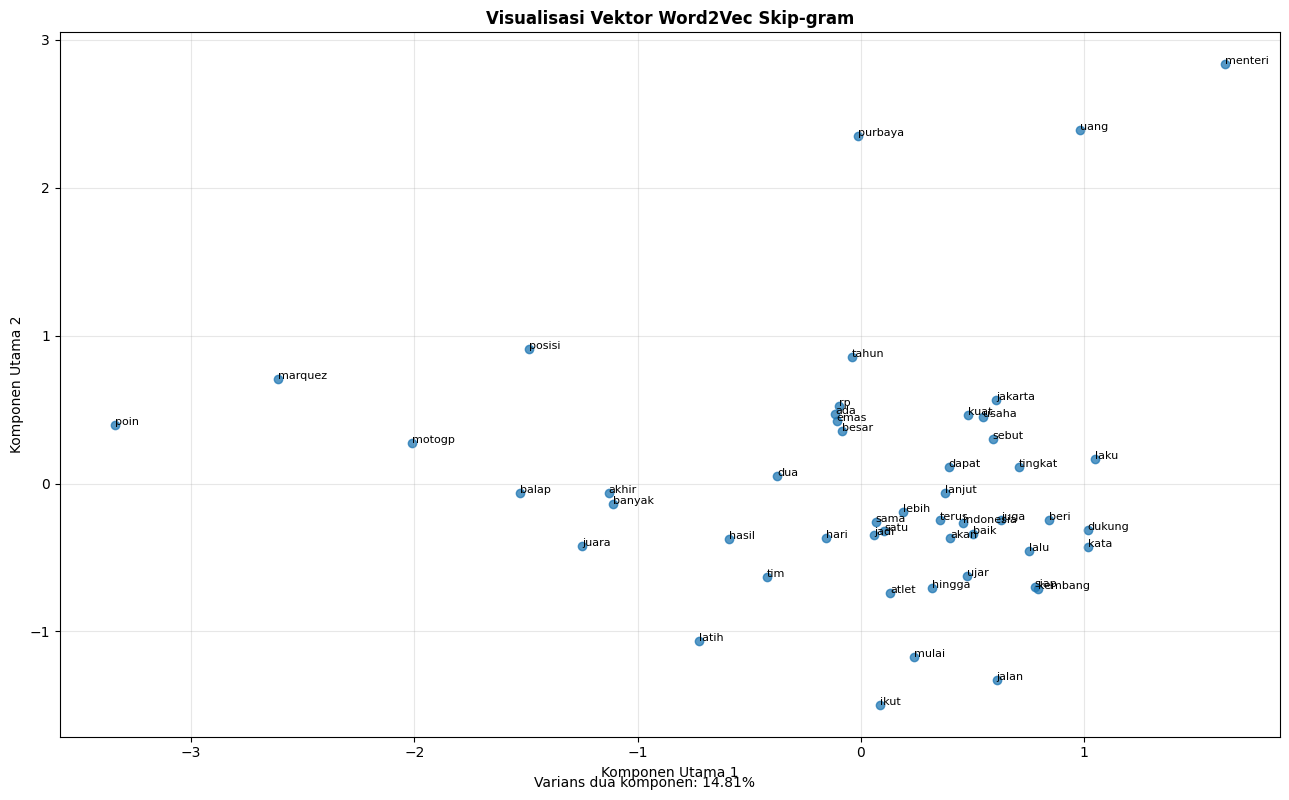


TAHAP 6: VEKTOR DOKUMEN
Shape vektor latih: (160, 100)
Shape vektor uji  : (40, 100)
Vektor nol latih  : 0
Vektor nol uji    : 0

TAHAP 7: REDUKSI DIMENSI PCA
Dimensi sebelum PCA: 100
Dimensi setelah PCA: 11
Varians dipertahankan: 86.30%

TAHAP 9: TF-IDF + LINEAR SVM
Parameter terbaik: {'svm__C': 0.1, 'tfidf__max_df': 0.95, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}
Macro F1 validasi silang: 100.00%

EVALUASI: Word2Vec + PCA + GaussianNB
              precision    recall  f1-score   support

     Finance       1.00      0.75      0.86        20
       Sport       0.80      1.00      0.89        20

    accuracy                           0.88        40
   macro avg       0.90      0.88      0.87        40
weighted avg       0.90      0.88      0.87        40


EVALUASI: Word2Vec + Logistic Regression
              precision    recall  f1-score   support

     Finance       0.95      0.95      0.95        20
       Sport       0.95      0.95      0.95        20

    accuracy     

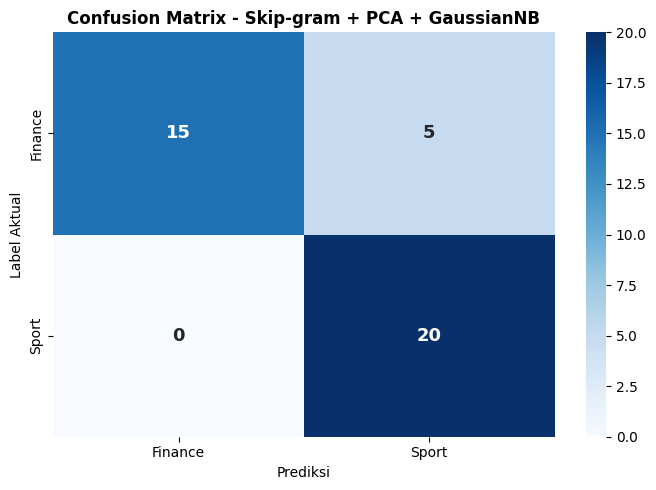

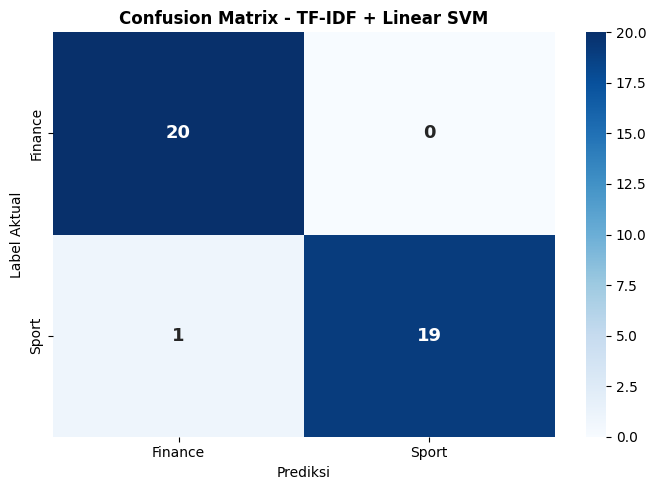


PREDIKSI BERITA BARU
Teks: IHSG ditutup menguat seiring peningkatan volume transaksi saham perbankan

Prediksi Word2Vec + PCA + GNB: Finance
Probabilitas keluaran GaussianNB:
Finance: 100.00%
Sport: 0.00%

Prediksi TF-IDF + Linear SVM: Finance

PROSES SELESAI
Folder hasil: hasil_perbaikan_skipgram
Artefak utama:
- w2v_model.model
- pca_model.pkl
- gnb_model.pkl
- metadata_model.pkl
- tfidf_svm_model.pkl
- word2vec_lr_model.pkl
- perbandingan_model.csv
- hasil_prediksi_data_uji.csv
- hasil_vektor_skipgram.csv
- hasil_kemiripan_skipgram.csv
- visualisasi_skipgram.png
- confusion_matrix_skipgram.png
- confusion_matrix_tfidf_svm.png


In [5]:

# ==============================================================================
# KLASIFIKASI BERITA DETIK
# WORD2VEC SKIP-GRAM + PCA + GAUSSIAN NAIVE BAYES
# DENGAN VALIDASI, PERBANDINGAN MODEL, DAN PREDIKSI BERITA BARU
# ==============================================================================

import os
import random
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from gensim.models import Word2Vec

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

# ==============================================================================
# KONFIGURASI
# ==============================================================================

SEED = 42
TEST_SIZE = 0.20

VECTOR_SIZE = 100
WINDOW = 5
EPOCHS = 20
MIN_COUNT = 1
PCA_VARIANCE = 0.85

DATA_PATH = "detik_preprocessed.csv"
OUTPUT_DIR = "hasil_perbaikan_skipgram"

os.makedirs(OUTPUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
warnings.filterwarnings("default")

LABEL_MAP = {"finance": 0, "sport": 1}
LABEL_NAMES = ["Finance", "Sport"]


# ==============================================================================
# TAHAP 1: MEMUAT DAN MEMBERSIHKAN DATASET
# ==============================================================================

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH)

required_columns = {"isi_berita_clean", "label"}
missing = required_columns - set(df.columns)

if missing:
    raise ValueError(
        f"Kolom yang diperlukan tidak tersedia: {missing}"
    )

df = df.dropna(subset=["label"]).copy()

df["label"] = (
    df["label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df["isi_berita_clean"] = (
    df["isi_berita_clean"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df = df[df["label"].isin(LABEL_MAP)].copy()

# Hapus teks kosong dan duplikat teks persis.
df = df[
    df["isi_berita_clean"].str.len() > 0
].copy()

df = df.drop_duplicates(
    subset=["isi_berita_clean"]
).reset_index(drop=True)

# Tokenisasi sesuai preprocessing dataset.
df["tokens"] = df["isi_berita_clean"].apply(
    lambda text: text.lower().split()
)

df = df[df["tokens"].map(len) > 0].reset_index(drop=True)

if df.empty:
    raise ValueError(
        "Tidak ada berita Finance atau Sport yang valid."
    )

if df["label"].nunique() != 2:
    raise ValueError(
        "Dataset harus memiliki kelas Finance dan Sport."
    )

df["label_encoded"] = df["label"].map(LABEL_MAP)

class_counts = df["label"].value_counts()

if class_counts.min() < 5:
    raise ValueError(
        "Setiap kelas membutuhkan minimal 5 berita agar "
        "pembagian data dan validasi silang lebih layak."
    )

print("=" * 75)
print("TAHAP 1: INFORMASI DATASET")
print("=" * 75)
print(f"Jumlah berita: {len(df)}")
print("\nDistribusi kelas:")
print(class_counts)

print("\nProporsi kelas (%):")
print((class_counts / len(df) * 100).round(2))


# ==============================================================================
# TAHAP 2: TRAIN-TEST SPLIT
# ==============================================================================

# Data uji hanya digunakan untuk evaluasi akhir.
# Jangan menggunakan hasil data uji untuk memilih parameter.

train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=df["label_encoded"],
)

train_df = df.iloc[train_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

sentences_train = train_df["tokens"].tolist()
sentences_test = test_df["tokens"].tolist()

texts_train = train_df["isi_berita_clean"].tolist()
texts_test = test_df["isi_berita_clean"].tolist()

y_train = train_df["label_encoded"].to_numpy(dtype=int)
y_test = test_df["label_encoded"].to_numpy(dtype=int)

print("\n" + "=" * 75)
print("TAHAP 2: PEMBAGIAN DATA")
print("=" * 75)
print(f"Data latih: {len(train_df)}")
print(f"Data uji  : {len(test_df)}")


# ==============================================================================
# TAHAP 3: MELATIH WORD2VEC SKIP-GRAM
# ==============================================================================

# Word2Vec hanya mempelajari teks data latih.
# workers=1 membantu reproduksibilitas hasil.

w2v_model = Word2Vec(
    sentences=sentences_train,
    vector_size=VECTOR_SIZE,
    window=WINDOW,
    min_count=MIN_COUNT,
    sg=1,
    workers=1,
    seed=SEED,
    epochs=EPOCHS,
    sample=1e-3,
)

w2v_model.save(
    os.path.join(OUTPUT_DIR, "w2v_model.model")
)

print("\n" + "=" * 75)
print("TAHAP 3: WORD2VEC SKIP-GRAM")
print("=" * 75)
print(f"Arsitektur       : Skip-gram")
print(f"Dimensi vektor   : {VECTOR_SIZE}")
print(f"Window           : {WINDOW}")
print(f"Epoch            : {EPOCHS}")
print(f"Min count        : {MIN_COUNT}")
print(f"Ukuran vocabulary: {len(w2v_model.wv)}")

print("\nContoh kosakata:")
print(w2v_model.wv.index_to_key[:20])


# ==============================================================================
# TAHAP 4: VEKTOR KATA DAN KEMIRIPAN
# ==============================================================================

kata_target = "saham"

if kata_target not in w2v_model.wv:
    kata_target = w2v_model.wv.index_to_key[0]

vektor_target = w2v_model.wv[kata_target]

print(f"\nVektor kata '{kata_target}':")
print(vektor_target)

similar_words = []

if len(w2v_model.wv) > 1:
    similar_words = w2v_model.wv.most_similar(
        kata_target,
        topn=min(10, len(w2v_model.wv) - 1),
    )

print(f"\nKata paling mirip dengan '{kata_target}':")

for word, score in similar_words:
    print(f"{word:<25} {score:.4f}")

vector_df = pd.DataFrame(
    [vektor_target],
    columns=[
        f"dimensi_{i+1}"
        for i in range(VECTOR_SIZE)
    ],
)

vector_df.insert(0, "kata", kata_target)

vector_df.to_csv(
    os.path.join(OUTPUT_DIR, "hasil_vektor_skipgram.csv"),
    index=False,
)

pd.DataFrame(
    similar_words,
    columns=["kata", "skor_kemiripan"],
).to_csv(
    os.path.join(OUTPUT_DIR, "hasil_kemiripan_skipgram.csv"),
    index=False,
)


# ==============================================================================
# TAHAP 5: VISUALISASI VEKTOR KATA
# ==============================================================================

jumlah_kata = min(50, len(w2v_model.wv))
kata_visual = w2v_model.wv.index_to_key[:jumlah_kata]

if len(kata_visual) >= 2:
    vektor_visual = np.array(
        [w2v_model.wv[word] for word in kata_visual]
    )

    pca_visual = PCA(
        n_components=2,
        random_state=SEED,
    )

    vektor_2d = pca_visual.fit_transform(vektor_visual)

    plt.figure(figsize=(13, 8))
    plt.scatter(
        vektor_2d[:, 0],
        vektor_2d[:, 1],
        alpha=0.75,
    )

    for i, word in enumerate(kata_visual):
        plt.annotate(
            word,
            (vektor_2d[i, 0], vektor_2d[i, 1]),
            fontsize=8,
        )

    variance_2d = (
        pca_visual.explained_variance_ratio_.sum() * 100
    )

    plt.title(
        "Visualisasi Vektor Word2Vec Skip-gram",
        fontweight="bold",
    )
    plt.xlabel("Komponen Utama 1")
    plt.ylabel("Komponen Utama 2")
    plt.figtext(
        0.5,
        0.01,
        f"Varians dua komponen: {variance_2d:.2f}%",
        ha="center",
    )
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        os.path.join(OUTPUT_DIR, "visualisasi_skipgram.png"),
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()


# ==============================================================================
# TAHAP 6: EKSTRAKSI VEKTOR DOKUMEN
# ==============================================================================

def get_document_vector(tokens, model):
    """
    Merata-ratakan vektor kata yang dikenal model Word2Vec.
    """

    valid_vectors = [
        model.wv[token]
        for token in tokens
        if token in model.wv
    ]

    if not valid_vectors:
        return np.zeros(
            model.vector_size,
            dtype=np.float32,
        )

    return np.mean(
        valid_vectors,
        axis=0,
        dtype=np.float32,
    )


X_train_vec = np.vstack([
    get_document_vector(tokens, w2v_model)
    for tokens in sentences_train
])

X_test_vec = np.vstack([
    get_document_vector(tokens, w2v_model)
    for tokens in sentences_test
])

zero_train = np.all(X_train_vec == 0, axis=1).sum()
zero_test = np.all(X_test_vec == 0, axis=1).sum()

print("\n" + "=" * 75)
print("TAHAP 6: VEKTOR DOKUMEN")
print("=" * 75)
print(f"Shape vektor latih: {X_train_vec.shape}")
print(f"Shape vektor uji  : {X_test_vec.shape}")
print(f"Vektor nol latih  : {zero_train}")
print(f"Vektor nol uji    : {zero_test}")


# ==============================================================================
# TAHAP 7: PCA UNTUK MODEL UTAMA
# ==============================================================================

pca_doc = PCA(
    n_components=PCA_VARIANCE,
    svd_solver="full",
)

X_train_pca = pca_doc.fit_transform(X_train_vec)
X_test_pca = pca_doc.transform(X_test_vec)

variance_retained = (
    pca_doc.explained_variance_ratio_.sum() * 100
)

print("\n" + "=" * 75)
print("TAHAP 7: REDUKSI DIMENSI PCA")
print("=" * 75)
print(f"Dimensi sebelum PCA: {X_train_vec.shape[1]}")
print(f"Dimensi setelah PCA: {X_train_pca.shape[1]}")
print(f"Varians dipertahankan: {variance_retained:.2f}%")

joblib.dump(
    pca_doc,
    os.path.join(OUTPUT_DIR, "pca_model.pkl"),
)


# ==============================================================================
# TAHAP 8: MODEL UTAMA GAUSSIAN NAIVE BAYES
# ==============================================================================

# Model utama sesuai rancangan penelitian.
nb_model = GaussianNB()
nb_model.fit(X_train_pca, y_train)

y_pred_gnb = nb_model.predict(X_test_pca)

joblib.dump(
    nb_model,
    os.path.join(OUTPUT_DIR, "gnb_model.pkl"),
)


# ==============================================================================
# TAHAP 9: VALIDASI SILANG DAN PEMILIHAN BASELINE TF-IDF + SVM
# ==============================================================================

# Pemilihan parameter hanya menggunakan data latih.
# GridSearchCV melatih ulang TF-IDF di setiap fold sehingga
# vocabulary dan IDF tidak bocor antarfold.

minimum_class_train = int(
    pd.Series(y_train).value_counts().min()
)

n_splits = min(5, minimum_class_train)

if n_splits < 2:
    raise ValueError(
        "Data latih tidak cukup untuk validasi silang."
    )

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=SEED,
)

svm_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            sublinear_tf=True,
            strip_accents=None,
        ),
    ),
    (
        "svm",
        LinearSVC(
            class_weight="balanced",
            random_state=SEED,
        ),
    ),
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "tfidf__max_df": [0.95, 1.0],
    "svm__C": [0.1, 1.0, 10.0],
}

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    error_score="raise",
)

svm_search.fit(texts_train, y_train)

svm_best = svm_search.best_estimator_
y_pred_svm = svm_best.predict(texts_test)

print("\n" + "=" * 75)
print("TAHAP 9: TF-IDF + LINEAR SVM")
print("=" * 75)
print(f"Parameter terbaik: {svm_search.best_params_}")
print(
    "Macro F1 validasi silang: "
    f"{svm_search.best_score_ * 100:.2f}%"
)

joblib.dump(
    svm_best,
    os.path.join(OUTPUT_DIR, "tfidf_svm_model.pkl"),
)


# ==============================================================================
# TAHAP 10: MODEL PEMBANDING WORD2VEC + LOGISTIC REGRESSION
# ==============================================================================

lr_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=SEED,
        ),
    ),
])

lr_model.fit(X_train_vec, y_train)
y_pred_lr = lr_model.predict(X_test_vec)

joblib.dump(
    lr_model,
    os.path.join(OUTPUT_DIR, "word2vec_lr_model.pkl"),
)


# ==============================================================================
# TAHAP 11: EVALUASI SELURUH MODEL
# ==============================================================================

predictions = {
    "Word2Vec + PCA + GaussianNB": y_pred_gnb,
    "Word2Vec + Logistic Regression": y_pred_lr,
    "TF-IDF + Linear SVM": y_pred_svm,
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, pred
        ),
        "Macro Precision": precision_score(
            y_test, pred,
            average="macro",
            zero_division=0,
        ),
        "Macro Recall": recall_score(
            y_test, pred,
            average="macro",
            zero_division=0,
        ),
        "Macro F1": f1_score(
            y_test, pred,
            average="macro",
            zero_division=0,
        ),
        "Weighted F1": f1_score(
            y_test, pred,
            average="weighted",
            zero_division=0,
        ),
    })

    print("\n" + "=" * 75)
    print(f"EVALUASI: {name}")
    print("=" * 75)

    print(
        classification_report(
            y_test,
            pred,
            labels=[0, 1],
            target_names=LABEL_NAMES,
            zero_division=0,
        )
    )

results_df = pd.DataFrame(results)

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "perbandingan_model.csv"),
    index=False,
)

print("\n" + "=" * 75)
print("PERBANDINGAN MODEL PADA DATA UJI")
print("=" * 75)
print(
    results_df.sort_values(
        "Macro F1",
        ascending=False,
    ).to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}",
    )
)


# ==============================================================================
# TAHAP 12: CONFUSION MATRIX MODEL UTAMA
# ==============================================================================

cm_gnb = confusion_matrix(
    y_test,
    y_pred_gnb,
    labels=[0, 1],
)

print("\nConfusion Matrix GaussianNB:")
print(cm_gnb)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_gnb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABEL_NAMES,
    yticklabels=LABEL_NAMES,
    annot_kws={"size": 13, "weight": "bold"},
)

plt.title(
    "Confusion Matrix - Skip-gram + PCA + GaussianNB",
    fontweight="bold",
)
plt.xlabel("Prediksi")
plt.ylabel("Label Aktual")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR, "confusion_matrix_skipgram.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ==============================================================================
# TAHAP 13: CONFUSION MATRIX MODEL TF-IDF + SVM
# ==============================================================================

cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=[0, 1],
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABEL_NAMES,
    yticklabels=LABEL_NAMES,
    annot_kws={"size": 13, "weight": "bold"},
)

plt.title(
    "Confusion Matrix - TF-IDF + Linear SVM",
    fontweight="bold",
)
plt.xlabel("Prediksi")
plt.ylabel("Label Aktual")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR, "confusion_matrix_tfidf_svm.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ==============================================================================
# TAHAP 14: MENYIMPAN PREDIKSI DATA UJI
# ==============================================================================

hasil_uji = test_df[
    ["isi_berita_clean", "label"]
].copy()

hasil_uji = hasil_uji.rename(
    columns={
        "isi_berita_clean": "teks",
        "label": "label_asli",
    }
)

for name, pred in predictions.items():
    column_name = (
        "prediksi_"
        + name.lower()
        .replace(" + ", "_")
        .replace(" ", "_")
    )

    hasil_uji[column_name] = [
        LABEL_NAMES[int(value)]
        for value in pred
    ]

hasil_uji.to_csv(
    os.path.join(
        OUTPUT_DIR, "hasil_prediksi_data_uji.csv"
    ),
    index=False,
)


# ==============================================================================
# TAHAP 15: MENYIMPAN METADATA MODEL UTAMA
# ==============================================================================

metadata = {
    "label_map": LABEL_MAP,
    "label_names": LABEL_NAMES,
    "vector_size": VECTOR_SIZE,
    "window": WINDOW,
    "epochs": EPOCHS,
    "min_count": MIN_COUNT,
    "pca_variance_threshold": PCA_VARIANCE,
    "seed": SEED,
    "main_model": "Word2Vec + PCA + GaussianNB",
    "preprocessing": (
        "Teks harus melalui preprocessing yang sama "
        "dengan isi_berita_clean pada data latih."
    ),
}

joblib.dump(
    metadata,
    os.path.join(OUTPUT_DIR, "metadata_model.pkl"),
)


# ==============================================================================
# TAHAP 16: FUNGSI PREDIKSI BERITA BARU - MODEL UTAMA
# ==============================================================================

def prediksi_teks_baru(
    teks,
    model_w2v,
    model_pca,
    model_gnb,
):
    """
    Prediksi menggunakan Word2Vec + PCA + GaussianNB.
    Teks harus sudah melalui preprocessing yang sama
    seperti data latih.
    """

    if not isinstance(teks, str) or not teks.strip():
        raise ValueError("Teks berita tidak boleh kosong.")

    tokens = teks.lower().split()

    known_tokens = [
        token for token in tokens
        if token in model_w2v.wv
    ]

    if not known_tokens:
        raise ValueError(
            "Tidak ada token yang dikenal model Word2Vec."
        )

    doc_vec = get_document_vector(
        tokens,
        model_w2v,
    )

    doc_pca = model_pca.transform(
        doc_vec.reshape(1, -1)
    )

    pred = int(model_gnb.predict(doc_pca)[0])
    prob = model_gnb.predict_proba(doc_pca)[0]

    probabilities = {
        LABEL_NAMES[int(class_id)]: float(value)
        for class_id, value in zip(
            model_gnb.classes_,
            prob,
        )
    }

    return LABEL_NAMES[pred], probabilities


# ==============================================================================
# TAHAP 17: FUNGSI PREDIKSI TF-IDF + SVM
# ==============================================================================

def prediksi_tfidf_svm(teks, model):
    """
    Model ini menerima teks yang telah melalui preprocessing
    yang sama seperti data latih TF-IDF.
    """

    if not isinstance(teks, str) or not teks.strip():
        raise ValueError("Teks berita tidak boleh kosong.")

    pred = int(model.predict([teks])[0])

    # LinearSVC tidak menyediakan predict_proba secara default.
    return LABEL_NAMES[pred]


# ==============================================================================
# TAHAP 18: PENGUJIAN BERITA BARU
# ==============================================================================

teks_sampel = (
    "IHSG ditutup menguat seiring peningkatan "
    "volume transaksi saham perbankan"
)

print("\n" + "=" * 75)
print("PREDIKSI BERITA BARU")
print("=" * 75)
print(f"Teks: {teks_sampel}")

try:
    kategori, probabilitas = prediksi_teks_baru(
        teks_sampel,
        w2v_model,
        pca_doc,
        nb_model,
    )

    print(f"\nPrediksi Word2Vec + PCA + GNB: {kategori}")
    print("Probabilitas keluaran GaussianNB:")

    for label, probability in probabilitas.items():
        print(f"{label}: {probability * 100:.2f}%")

    kategori_svm = prediksi_tfidf_svm(
        teks_sampel,
        svm_best,
    )

    print(f"\nPrediksi TF-IDF + Linear SVM: {kategori_svm}")

except ValueError as error:
    print(f"Prediksi gagal: {error}")


# ==============================================================================
# TAHAP 19: RINGKASAN OUTPUT
# ==============================================================================

print("\n" + "=" * 75)
print("PROSES SELESAI")
print("=" * 75)
print(f"Folder hasil: {OUTPUT_DIR}")
print("Artefak utama:")
print("- w2v_model.model")
print("- pca_model.pkl")
print("- gnb_model.pkl")
print("- metadata_model.pkl")
print("- tfidf_svm_model.pkl")
print("- word2vec_lr_model.pkl")
print("- perbandingan_model.csv")
print("- hasil_prediksi_data_uji.csv")
print("- hasil_vektor_skipgram.csv")
print("- hasil_kemiripan_skipgram.csv")
print("- visualisasi_skipgram.png")
print("- confusion_matrix_skipgram.png")
print("- confusion_matrix_tfidf_svm.png")
